<a href="https://colab.research.google.com/github/kalxdoc/credit-default-ann/blob/main/ANN_credit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Default Prediction with an ANN
**Dataset:** Default of Credit Card Clients (UCI id 350): 30,000 customers, 23 numeric features (credit limit, demographics, 6 months of repayment status, bills and payments). Target: does the customer default next month (1) or not (0)?

Pipeline: 1 dataset, 2 ANN, 3 confusion matrix + report, 4 loss vs accuracy, 5 store model, 6 single-page website, 7 live deploy.

## 1. Dataset (classification, recent + large)

In [1]:
!pip install -q ucimlrepo
import numpy as np, pandas as pd, json
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=350)               # Default of Credit Card Clients
X = ds.data.features.copy()
y = ds.data.targets.iloc[:, 0].astype(int).values

# UCI names the columns X1..X23; give them readable names (same order as the UCI description)
assert X.shape[1] == 23
X.columns = (['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
             + [f'PAY_{i}' for i in range(1, 7)]
             + [f'BILL_AMT{i}' for i in range(1, 7)]
             + [f'PAY_AMT{i}' for i in range(1, 7)])

print("Shape:", X.shape)
print("Class balance:\n", pd.Series(y).value_counts(normalize=True).round(3))
X.head()

Shape: (30000, 23)
Class balance:
 0    0.779
1    0.221
Name: proportion, dtype: float64


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# Only ~22% of customers default, so weight the classes to stop the model ignoring them
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print(class_weight)

{0: np.float64(0.6420202236370446), 1: np.float64(2.2603126765869277)}


## 2. ANN model build

In [3]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)
ann = Sequential([
    Input(shape=(X_train_s.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid'),      # P(default)
])
ann.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
ann.summary()

hist = ann.fit(
    X_train_s, y_train,
    validation_split=0.2,
    epochs=50, batch_size=256,
    class_weight=class_weight,
    callbacks=[EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)],
    verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,649 (14.25 KB)

 Trainable params: 3,649 (14.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
75/75 - 5s - 71ms/step - accuracy: 0.5824 - loss: 0.6636 - val_accuracy: 0.6798 - val_loss: 0.6352
Epoch 2/50
75/75 - 1s - 7ms/step - accuracy: 0.6898 - loss: 0.6207 - val_accuracy: 0.7573 - val_loss: 0.6104
Epoch 3/50
75/75 - 1s - 12ms/step - accuracy: 0.7326 - loss: 0.6064 - val_accuracy: 0.7646 - val_loss: 0.5974
Epoch 4/50
75/75 - 1s - 14ms/step - accuracy: 0.7503 - loss: 0.5968 - val_accuracy: 0.7769 - val_loss: 0.5853
Epoch 5/50
75/75 - 1s - 18ms/step - accuracy: 0.7618 - loss: 0.5895 - val_accuracy: 0.7746 - val_loss: 0.5854
Epoch 6/50
75/75 - 1s - 16ms/step - accuracy: 0.7578 - loss: 0.5889 - val_accuracy: 0.7779 - val_loss: 0.5743
Epoch 7/50
75/75 - 1s - 10ms/step - accuracy: 0.7629 - loss: 0.5838 - val_accuracy: 0.7773 - val_loss: 0.5771
Epoch 8/50
75/75 - 1s - 8ms/step - accuracy: 0.7645 - loss: 0.5808 - val_accuracy: 0.7763 - val_loss: 0.5695
Epoch 9/50
75/75 - 1s - 13ms/step - accuracy: 0.7596 - loss: 0.5812 - val_accuracy: 0.7767 - val_loss: 0.5678
Epoch 10/50


## 3. Confusion matrix and classification report

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


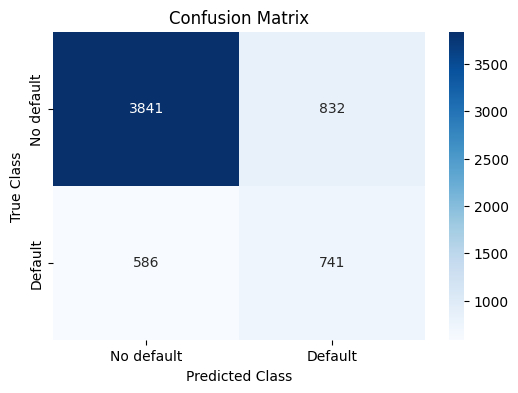

              precision    recall  f1-score   support

  No default       0.87      0.82      0.84      4673
     Default       0.47      0.56      0.51      1327

    accuracy                           0.76      6000
   macro avg       0.67      0.69      0.68      6000
weighted avg       0.78      0.76      0.77      6000



In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

y_prob = ann.predict(X_test_s, batch_size=2048).ravel()
y_hat  = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_hat)
labels = ['No default', 'Default']
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Class'); plt.ylabel('True Class'); plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(classification_report(y_test, y_hat, target_names=labels))

## 4. Loss vs accuracy graph

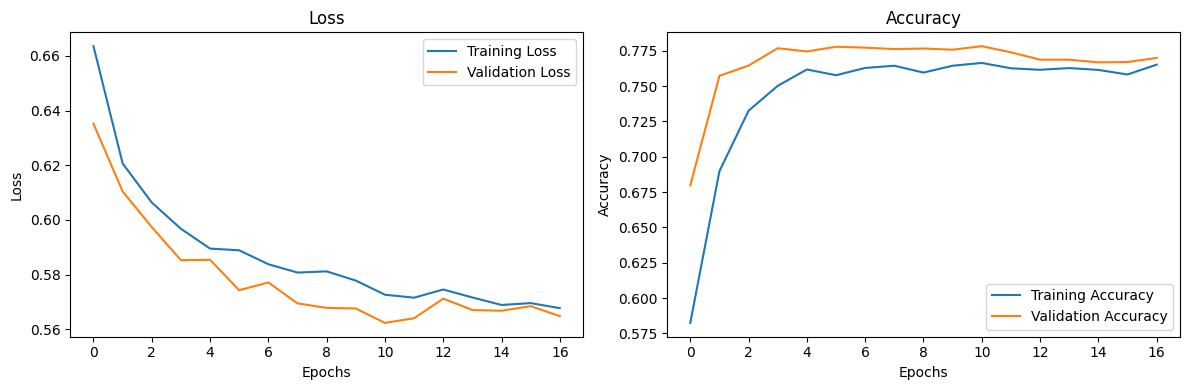

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history['loss'], label='Training Loss')
axes[0].plot(hist.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Loss'); axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(hist.history['accuracy'], label='Training Accuracy')
axes[1].plot(hist.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('Accuracy'); axes[1].legend()
plt.tight_layout()
plt.savefig('loss_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Store the model

In [6]:
import joblib
ann.save('credit_default_ann.keras')
joblib.dump(scaler, 'credit_scaler.joblib')

# Weights as plain JSON so the website can run the ANN in the browser (no server needed)
dense = [l for l in ann.layers if isinstance(l, Dense)]
model_json = {
    "features":  list(X.columns),
    "mean":      scaler.mean_.round(6).tolist(),
    "scale":     scaler.scale_.round(6).tolist(),
    "threshold": 0.5,
    "layers": [{
        "activation": l.get_config()["activation"],
        "kernel": l.get_weights()[0].round(6).tolist(),
        "bias":   l.get_weights()[1].round(6).tolist(),
    } for l in dense],
}
json.dump(model_json, open('model.json', 'w'))

reloaded = tf.keras.models.load_model('credit_default_ann.keras')
print("Max diff after reload:", np.abs(reloaded.predict(X_test_s[:100]) - ann.predict(X_test_s[:100])).max())

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
Max diff after reload: 0.0


## 6. Single-page website (form input, prediction output)
This cell writes `index.html` with the trained weights embedded, so it is one self-contained file.

In [7]:
HTML_TEMPLATE = r'''
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Credit Default Predictor (ANN)</title>
<style>
:root{--bg:#f6f7f9;--card:#fff;--text:#1d2430;--muted:#667085;--line:#e1e5ea;--accent:#2563eb;--good:#16a34a;--bad:#dc2626}
@media (prefers-color-scheme:dark){:root{--bg:#12151a;--card:#1b2028;--text:#e8ebf0;--muted:#98a2b3;--line:#2c333d;--accent:#5b8cff;--good:#34d399;--bad:#f87171}}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--text);font:16px/1.5 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
main{max-width:860px;margin:0 auto;padding:28px 16px 48px}
h1{font-size:1.6rem;margin:0 0 4px}
p.sub{color:var(--muted);margin:0 0 20px}
.card{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:20px}
.grid{display:grid;grid-template-columns:repeat(auto-fill,minmax(230px,1fr));gap:14px}
label{display:block;font-size:.85rem;color:var(--muted);margin-bottom:4px}
input,select{width:100%;padding:9px 10px;border:1px solid var(--line);border-radius:8px;background:var(--bg);color:var(--text);font:inherit}
button{margin-top:20px;width:100%;padding:12px;border:0;border-radius:8px;background:var(--accent);color:#fff;font:inherit;font-weight:600;cursor:pointer}
button:hover{opacity:.92}
#result{margin-top:20px;display:none}
.bar{height:14px;background:var(--line);border-radius:7px;overflow:hidden;margin:10px 0}
.bar>div{height:100%;width:0;transition:width .4s}
.big{font-size:1.4rem;font-weight:700}
.note{color:var(--muted);font-size:.8rem;margin-top:16px}
#err{color:var(--bad);margin-top:12px}
</style>
</head>
<body>
<main>
<h1>Credit Card Default Predictor</h1>
<p class="sub">An ANN trained on 30,000 credit card clients (UCI Default of Credit Card Clients). Fill in the form and press Predict.</p>
<form id="f" class="card" autocomplete="off">
  <div class="grid" id="fields"></div>
  <button type="submit">Predict</button>
  <div id="err"></div>
</form>
<div id="result" class="card">
  <div class="big" id="label"></div>
  <div class="bar"><div id="fill"></div></div>
  <div id="prob"></div>
</div>
<p class="note">Educational project, not financial advice. The model runs entirely in your browser; nothing is sent anywhere.</p>
</main>
<script>
const MODEL = /*MODEL_JSON*/null;

const PAYOPT = [[-2,"-2 - No consumption"],[-1,"-1 - Paid in full"],[0,"0 - Revolving credit"],[1,"1 - 1 month late"],[2,"2 - 2 months late"],[3,"3 - 3 months late"],[4,"4 - 4 months late"],[5,"5 - 5 months late"],[6,"6 - 6 months late"],[7,"7 - 7 months late"],[8,"8+ months late"]];
const MONTHS = ["Sep","Aug","Jul","Jun","May","Apr"];   // 1 = most recent month
const FIELDS = {
  LIMIT_BAL:["Credit limit (NT$)","number",0,null,50000],
  SEX:["Sex",[[1,"Male"],[2,"Female"]]],
  EDUCATION:["Education",[[1,"Graduate school"],[2,"University"],[3,"High school"],[4,"Other"]]],
  MARRIAGE:["Marital status",[[1,"Married"],[2,"Single"],[3,"Other"]]],
  AGE:["Age","number",18,100,35]
};
for(let i=1;i<=6;i++){
  FIELDS["PAY_"+i]=["Repayment status, "+MONTHS[i-1],PAYOPT];
  FIELDS["BILL_AMT"+i]=["Bill amount, "+MONTHS[i-1]+" (NT$)","number",null,null,20000];
  FIELDS["PAY_AMT"+i]=["Amount paid, "+MONTHS[i-1]+" (NT$)","number",0,null,2000];
}
const DEFAULTS = {SEX:2,EDUCATION:2,MARRIAGE:2};

const box = document.getElementById("fields");
const names = MODEL ? MODEL.features : Object.keys(FIELDS);
names.forEach(n=>{
  const d = FIELDS[n]; if(!d) return;
  const w = document.createElement("div");
  let h = `<label for="${n}">${d[0]}</label>`;
  if(d[1]==="number") h += `<input id="${n}" type="number" ${d[2]==null?"":`min="${d[2]}"`} ${d[3]==null?"":`max="${d[3]}"`} step="any" value="${d[4]}" required>`;
  else h += `<select id="${n}">` + d[1].map(([v,t])=>`<option value="${v}"${(DEFAULTS[n]??0)==v?" selected":""}>${t}</option>`).join("") + `</select>`;
  w.innerHTML = h; box.appendChild(w);
});

function forward(x){
  let a = x;
  for(const L of MODEL.layers){
    const out = L.bias.map((b,j)=>{ let s=b; for(let i=0;i<a.length;i++) s+=a[i]*L.kernel[i][j]; return s; });
    if(L.activation==="relu") a = out.map(v=>Math.max(0,v));
    else if(L.activation==="sigmoid") a = out.map(v=>1/(1+Math.exp(-v)));
    else if(L.activation==="softmax"){ const m=Math.max(...out), e=out.map(v=>Math.exp(v-m)), s=e.reduce((p,c)=>p+c,0); a=e.map(v=>v/s); }
    else a = out;
  }
  return a;
}
function predict(values){
  const z = MODEL.features.map((n,i)=>(values[n]-MODEL.mean[i])/MODEL.scale[i]);
  return forward(z)[0];
}
document.getElementById("f").addEventListener("submit",e=>{
  e.preventDefault();
  const err = document.getElementById("err"); err.textContent="";
  if(!MODEL){ err.textContent="No model embedded. Run the notebook's website cell to generate index.html."; return; }
  const v = {}; MODEL.features.forEach(n=>v[n]=parseFloat(document.getElementById(n).value));
  const p = predict(v), thr = MODEL.threshold ?? 0.5, high = p>=thr;
  document.getElementById("result").style.display="block";
  const lab = document.getElementById("label");
  lab.textContent = high ? "Likely to default next month" : "Unlikely to default next month";
  lab.style.color = high ? "var(--bad)" : "var(--good)";
  const fill = document.getElementById("fill");
  fill.style.width = (p*100).toFixed(1)+"%"; fill.style.background = high ? "var(--bad)" : "var(--good)";
  document.getElementById("prob").textContent = `Model probability: ${(p*100).toFixed(1)}% (decision threshold ${(thr*100).toFixed(0)}%)`;
});
if(typeof module!=="undefined") module.exports={predict,forward};
</script>
</body>
</html>
'''

html = HTML_TEMPLATE.replace('/*MODEL_JSON*/null', json.dumps(model_json))
open('index.html', 'w', encoding='utf-8').write(html)
print('index.html written:', round(len(html)/1024), 'KB')

index.html written: 83 KB


In [8]:
# Cross-check: the website's math (numpy version of what the JS does) vs Keras
def web_forward(row):
    a = (row - np.array(model_json['mean'])) / np.array(model_json['scale'])
    for L in model_json['layers']:
        a = a @ np.array(L['kernel']) + np.array(L['bias'])
        a = np.maximum(a, 0) if L['activation'] == 'relu' else 1/(1+np.exp(-a))
    return a[0]
row = X_test.iloc[0].values.astype(float)
print("Website:", web_forward(row), "| Keras:", float(ann.predict(X_test_s[:1])[0, 0]))

# Download the files from Colab
from google.colab import files
for f in ['index.html', 'credit_default_ann.keras', 'model.json', 'confusion_matrix.png', 'loss_accuracy.png']:
    files.download(f)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Website: 0.3182392007563656 | Keras: 0.3182392120361328


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Make it live
**Option A, GitHub Pages (free link):**
1. Create a new GitHub repo, e.g. `credit-default-ann`, and upload `index.html` (plus the notebook and model file if you like).
2. Repo **Settings → Pages → Build and deployment → Source: Deploy from a branch → `main` / `(root)` → Save**.
3. After about a minute the site is live at `https://<your-username>.github.io/credit-default-ann/`.

**Option B, HTML live:** just double-click `index.html`. It works offline because the model is embedded.